# GSM8956239 · Xenium Single-Sample QC (v2 notebook)

**Data:** GSE295730 / GSM8956239  
**Environment:** spatial (py3.10) · scanpy 1.11.5 · squidpy 1.6.5  
**Before running:** Launch on a compute node (`srun --mem=16G ...`), not on head node  
**Rule:** No cells are filtered and no cell types are assigned. Output directories are versioned; change `VERSION` to re-run.

In [2]:
%matplotlib inline
from pathlib import Path

SAMPLE_ID = "GSM8956239"
VERSION   = "v1"          # change to v2, v3 ... when re-running; never overwrite
DATA      = Path("/network/rit/lab/meng_lab/Public_data/GSE295730/extracted/GSM8956239")
WORK      = Path("/network/rit/lab/meng_lab/YS/workfolder")
OUT       = WORK / "results" / f"{SAMPLE_ID}_qc_{VERSION}"

if OUT.exists():
    raise FileExistsError(f"Output directory already exists, bump VERSION: {OUT}")
OUT.mkdir(parents=True)
print(f"Output directory: {OUT}")

Output directory: /network/rit/lab/meng_lab/YS/workfolder/results/GSM8956239_qc_v1


## 1. Experiment Metadata

In [3]:
import json

exp = json.loads((DATA / "experiment.xenium").read_text())
for k, v in exp.items():
    print(f"{k:45s}: {v}")

major_version                                : 5
minor_version                                : 0
patch_version                                : 0
run_name                                     : SARAH_STANLEY
run_start_time                               : 2024-09-03T17:55:40Z
region_name                                  : v2
preservation_method                          : ffpe
num_cells                                    : 68273
transcripts_per_cell                         : 352
transcripts_per_100um                        : 295.4073051142696
region_area                                  : 31038067.698124997
total_cell_area                              : 11195583.327638716
thickness_of_high_quality_decoded_transcripts: 4.014712805706926
nuclear_transcripts_per_100um                : 539.0816953373999
fraction_transcripts_assigned                : 0.6982531158046691
segmented_cell_stain_frac                    : 0.0
segmented_cell_boundary_frac                 : 0.0
segmented_cell_interior

## 2. Official QC Metrics

In [4]:
import pandas as pd

m_raw = pd.read_csv(DATA / "metrics_summary.csv")
m = m_raw.iloc[0]                       # one row of official metrics, keep for later cells
metrics = m_raw.T
metrics.columns = ["Value"]
metrics

,Value
run_name,SARAH_STANLEY
cassette_name,REP1
region_name,v2
panel_name,mBrain_100g
panel_design_id,C728YM
predesigned_panel_id,mBrain_v1.1
region_area,31038067.698125
total_cell_area,11195583.327639
total_high_quality_decoded_transcripts,47364731
fraction_transcripts_decoded_q20,0.91509


## 3. Load Data (scanpy)

In [5]:
import scanpy as sc
import numpy as np

sc.settings.verbosity = 2

adata = sc.read_10x_h5(DATA / "cell_feature_matrix.h5")
print(adata)
print(f"\nCells:    {adata.n_obs:,}")
print(f"Features: {adata.n_vars:,}")
print("\nFeature types:")
print(adata.var["feature_types"].value_counts())

reading /network/rit/lab/meng_lab/Public_data/GSE295730/extracted/GSM8956239/cell_feature_matrix.h5
 (0:00:00)
AnnData object with n_obs × n_vars = 68273 × 347
    var: 'gene_ids', 'feature_types', 'genome'

Cells:    68,273
Features: 347

Feature types:
feature_types
Gene Expression    347
Name: count, dtype: int64


In [6]:
# Keep Gene Expression features only
adata = adata[:, adata.var["feature_types"] == "Gene Expression"].copy()
print(f"Gene Expression features: {adata.n_vars}")
print(f"Panel gene examples: {list(adata.var_names[:10])}")

Gene Expression features: 347
Panel gene examples: ['2010300C02Rik', 'Acsbg1', 'Acta2', 'Acvrl1', 'Adamts2', 'Adamtsl1', 'Adcyap1', 'Adgrl4', 'Aldh1a2', 'Angpt1']


In [7]:
# Add cell metadata. Strict ID check instead of a silent left join.
cells = pd.read_parquet(DATA / "cells.parquet")
cells["cell_id"] = cells["cell_id"].astype(str)
assert cells["cell_id"].is_unique, "Duplicate cell_id in cells.parquet"
assert set(cells["cell_id"]) == set(adata.obs_names), "cell ID mismatch between matrix and cells.parquet"
cells = cells.set_index("cell_id").loc[adata.obs_names]   # reorder to matrix order by ID, not by position

print("cells.parquet columns:", cells.columns.tolist())

keep = [c for c in ["x_centroid", "y_centroid", "cell_area", "nucleus_area",
                    "transcript_counts", "control_probe_counts",
                    "control_codeword_counts", "segmentation_method"]
        if c in cells.columns]
adata.obs = adata.obs.join(cells[keep])
adata.obsm["spatial"] = adata.obs[["x_centroid", "y_centroid"]].to_numpy()
assert np.isfinite(adata.obsm["spatial"]).all(), "Non-finite coordinates"

print("Columns joined into obs:", keep)
print("Coordinate range:")
print(f"  x: {adata.obs['x_centroid'].min():.1f} ~ {adata.obs['x_centroid'].max():.1f} um")
print(f"  y: {adata.obs['y_centroid'].min():.1f} ~ {adata.obs['y_centroid'].max():.1f} um")

cells.parquet columns: ['x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method']
Columns joined into obs: ['x_centroid', 'y_centroid', 'cell_area', 'nucleus_area', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'segmentation_method']
Coordinate range:
  x: 5.0 ~ 8445.9 um
  y: 5.7 ~ 4352.2 um


## 4. QC Metrics

In [8]:
sc.pp.calculate_qc_metrics(adata, percent_top=None, inplace=True)

print(f"Median transcripts per cell:    {adata.obs['total_counts'].median():.0f}")
print(f"Median genes detected per cell: {adata.obs['n_genes_by_counts'].median():.0f}")
print(f"Cells with 0 transcripts:       {(adata.obs['total_counts'] == 0).sum():,}")

desc_cols = ["total_counts", "n_genes_by_counts"] + [c for c in ["cell_area", "nucleus_area"] if c in adata.obs.columns]
adata.obs[desc_cols].describe()

Median transcripts per cell:    351
Median genes detected per cell: 94
Cells with 0 transcripts:       201


,total_counts,n_genes_by_counts,cell_area,nucleus_area
count,68273.000000,68273.000000,68273.000000,68273.000000
mean,484.416534,93.781905,163.982589,36.959181
std,380.139832,37.156028,62.725965,23.147261
min,0.000000,0.000000,7.812032,2.257813
25%,186.000000,64.000000,119.483442,20.139688
50%,351.000000,94.000000,158.724225,31.744845
75%,716.000000,125.000000,201.532351,49.084846
max,2715.000000,193.000000,478.024080,182.837663


## 4b. Cross-check Against Official Metrics

In [9]:
expected = m["total_high_quality_decoded_transcripts"] * exp["fraction_transcripts_assigned"]
matrix_total = float(adata.X.sum())
print(f"Matrix total transcripts:             {matrix_total:,.0f}")
print(f"Official decoded x assigned fraction: {expected:,.0f}")
print(f"Relative difference:                  {abs(matrix_total - expected) / expected:.2e}")
print(f"\nCells: matrix {adata.n_obs:,} vs experiment.xenium num_cells {exp['num_cells']:,}")
if "transcript_counts" in adata.obs.columns:
    print("cells.parquet transcript_counts sum:  "
          f"{adata.obs['transcript_counts'].sum():,.0f}")

Matrix total transcripts:             33,072,570
Official decoded x assigned fraction: 33,072,571
Relative difference:                  3.02e-08

Cells: matrix 68,273 vs experiment.xenium num_cells 68,273
cells.parquet transcript_counts sum:  33,072,571


## 5. QC Distributions

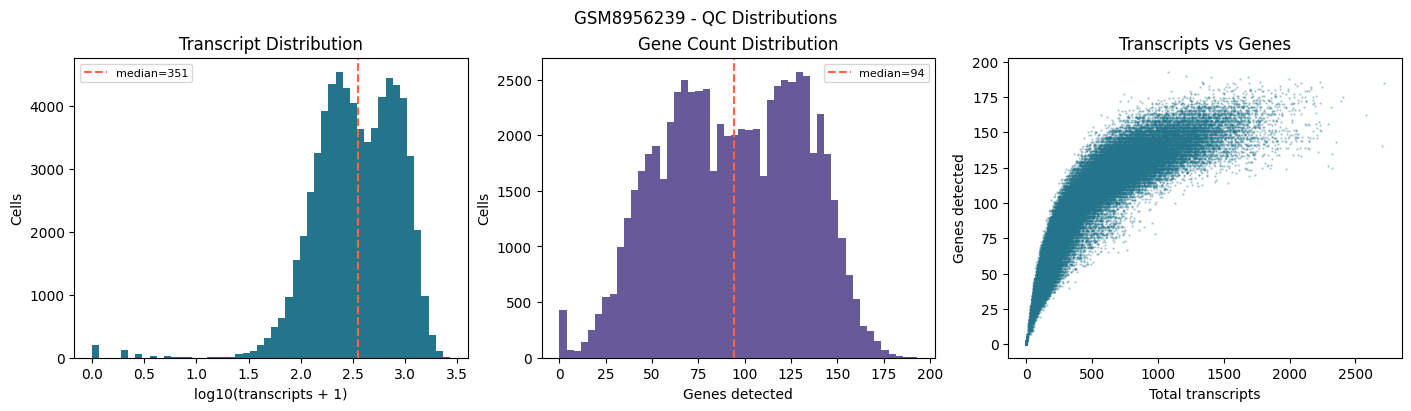

Saved -> /network/rit/lab/meng_lab/YS/workfolder/results/GSM8956239_qc_v1/qc_distributions.png


In [10]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)

# Transcript distribution
axes[0].hist(np.log10(adata.obs["total_counts"] + 1), bins=50, color="#24758B", edgecolor="none")
axes[0].axvline(np.log10(adata.obs["total_counts"].median() + 1), color="tomato", ls="--",
                label=f"median={adata.obs['total_counts'].median():.0f}")
axes[0].set(xlabel="log10(transcripts + 1)", ylabel="Cells", title="Transcript Distribution")
axes[0].legend(fontsize=8)

# Gene count distribution
axes[1].hist(adata.obs["n_genes_by_counts"], bins=50, color="#665A9B", edgecolor="none")
axes[1].axvline(adata.obs["n_genes_by_counts"].median(), color="tomato", ls="--",
                label=f"median={adata.obs['n_genes_by_counts'].median():.0f}")
axes[1].set(xlabel="Genes detected", ylabel="Cells", title="Gene Count Distribution")
axes[1].legend(fontsize=8)

# Transcripts vs genes scatter
axes[2].scatter(adata.obs["total_counts"], adata.obs["n_genes_by_counts"],
                s=0.5, alpha=0.3, color="#24758B", rasterized=True)
axes[2].set(xlabel="Total transcripts", ylabel="Genes detected", title="Transcripts vs Genes")

fig.suptitle(f"{SAMPLE_ID} - QC Distributions")
fig.savefig(OUT / "qc_distributions.png", dpi=180)
plt.show()
print(f"Saved -> {OUT}/qc_distributions.png")

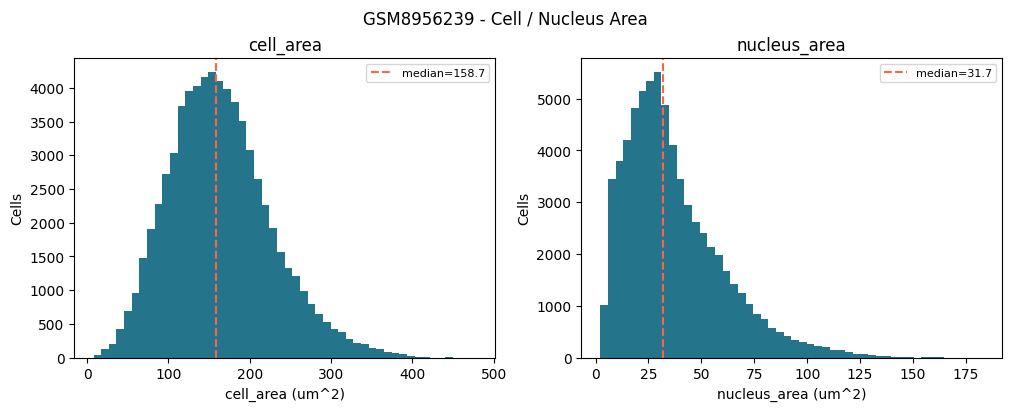

In [11]:
# Cell and nucleus area (only if present in cells.parquet)
area_cols = [c for c in ["cell_area", "nucleus_area"] if c in adata.obs.columns]
if area_cols:
    fig, axes = plt.subplots(1, len(area_cols), figsize=(5 * len(area_cols), 4),
                             squeeze=False, constrained_layout=True)
    for ax, col in zip(axes[0], area_cols):
        ax.hist(adata.obs[col], bins=50, color="#24758B", edgecolor="none")
        ax.axvline(adata.obs[col].median(), color="tomato", ls="--",
                   label=f"median={adata.obs[col].median():.1f}")
        ax.set(xlabel=f"{col} (um^2)", ylabel="Cells", title=col)
        ax.legend(fontsize=8)
    fig.suptitle(f"{SAMPLE_ID} - Cell / Nucleus Area")
    fig.savefig(OUT / "area_distributions.png", dpi=180)
    plt.show()
else:
    print("No area columns in cells.parquet")

## 6. Spatial Scatter Plot

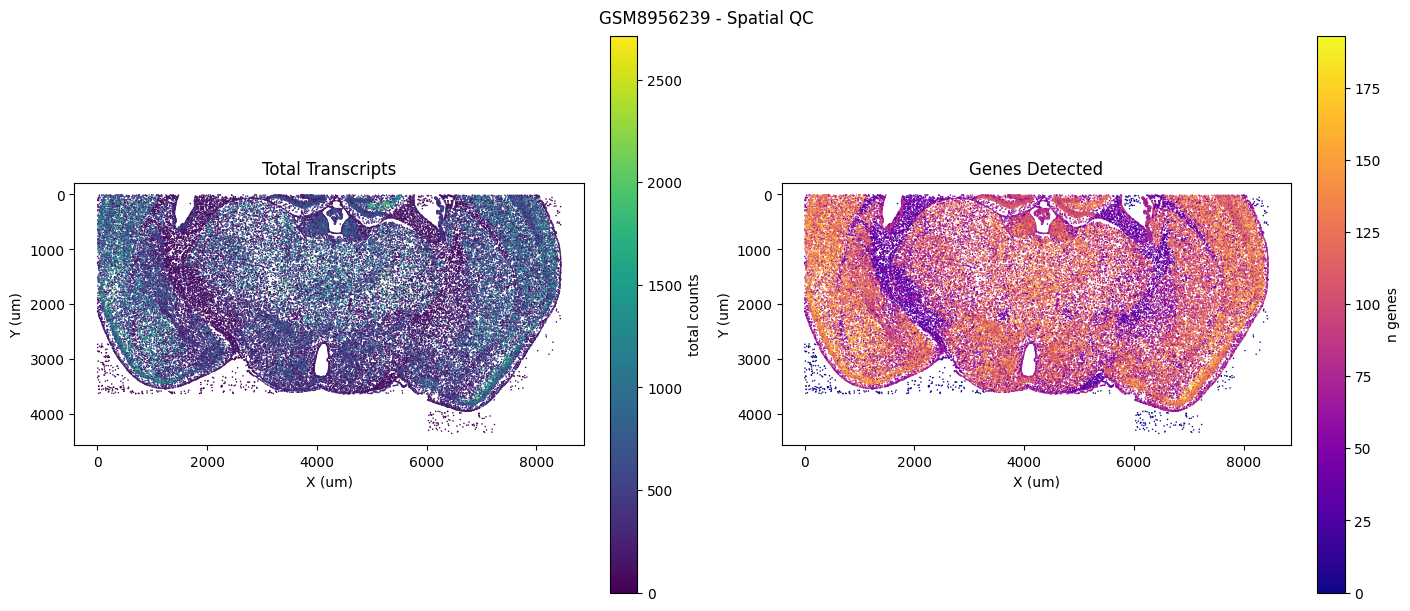

Saved -> /network/rit/lab/meng_lab/YS/workfolder/results/GSM8956239_qc_v1/spatial_qc.png


In [12]:
xy = adata.obsm["spatial"]

fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)

sc1 = axes[0].scatter(xy[:, 0], xy[:, 1],
                      c=adata.obs["total_counts"],
                      s=1.2, linewidths=0, cmap="viridis", rasterized=True)
axes[0].set(title="Total Transcripts", xlabel="X (um)", ylabel="Y (um)")
axes[0].set_aspect("equal")
axes[0].invert_yaxis()
fig.colorbar(sc1, ax=axes[0], label="total counts")

sc2 = axes[1].scatter(xy[:, 0], xy[:, 1],
                      c=adata.obs["n_genes_by_counts"],
                      s=1.2, linewidths=0, cmap="plasma", rasterized=True)
axes[1].set(title="Genes Detected", xlabel="X (um)", ylabel="Y (um)")
axes[1].set_aspect("equal")
axes[1].invert_yaxis()
fig.colorbar(sc2, ax=axes[1], label="n genes")

fig.suptitle(f"{SAMPLE_ID} - Spatial QC")
fig.savefig(OUT / "spatial_qc.png", dpi=180)
plt.show()
print(f"Saved -> {OUT}/spatial_qc.png")

## 7. Morphology Image Metadata

In [13]:
import re
import tifffile

PX_UM = exp.get("pixel_size", 0.2125)

with tifffile.TiffFile(DATA / "morphology.ome.tif") as tif:
    p0 = tif.pages[0]
    series = tif.series[0]
    meta = tif.ome_metadata or ""
    sizes = dict(re.findall(r'Size([XYZCT])="(\d+)"', meta))
    channel_names = re.findall(r'Name="([^"]+)"', meta)
    n_pages = len(tif.pages)
    print(f"Total TIFF pages:       {n_pages}")
    print(f"Series axes / shape:    {series.axes} {series.shape}")
    print(f"OME sizes (X,Y,Z,C,T):  {sizes}")
    print(f"Page 0 shape (H x W):   {p0.shape}")
    print(f"Data type:              {p0.dtype}")
    print(f"Channel names:          {channel_names}")
    px = re.findall(r'PhysicalSize[XY]="([^"]+)"', meta)
    units = re.findall(r'PhysicalSize[XY]Unit="([^"]+)"', meta)
    print(f"Physical pixel size:    {px} {units}")

H, W = p0.shape
print(f"\nImage extent:           {W * PX_UM:,.0f} x {H * PX_UM:,.0f} um")
print(f"Cell coordinate max:    {adata.obs['x_centroid'].max():,.0f} x {adata.obs['y_centroid'].max():,.0f} um")

img_info = {"tiff_pages": int(n_pages),
            "axes": series.axes, "series_shape": list(series.shape),
            "ome_sizes": sizes, "channel_names": channel_names,
            "height_px": int(H), "width_px": int(W), "pixel_size_um": PX_UM}
# If SizeZ > 1 and SizeC == 1, the pages are z-planes of one channel, not separate channels.

Total TIFF pages:       12
Series axes / shape:    ZYX (12, 20508, 39782)
OME sizes (X,Y,Z,C,T):  {'X': '39782', 'Y': '20508', 'Z': '12', 'C': '1', 'T': '1'}
Page 0 shape (H x W):   (20508, 39782)
Data type:              uint16
Channel names:          ['DAPI']
Physical pixel size:    ['0.2125', '0.2125'] ['µm', 'µm']

Image extent:           8,454 x 4,358 um
Cell coordinate max:    8,446 x 4,352 um


## 8. File Inventory

In [14]:
inv = pd.DataFrame(
    [(p.name, p.stat().st_size / 1e9) for p in sorted(DATA.iterdir()) if p.is_file()],
    columns=["file", "GB"])
inv.loc[len(inv)] = ["TOTAL", inv["GB"].sum()]
inv.to_csv(OUT / "file_inventory.tsv", sep="\t", index=False)
print("Image-like files (check for anything other than morphology.ome.tif, e.g. H&E):")
print([p.name for p in sorted(DATA.iterdir())
       if p.suffix.lower() in {".tif", ".tiff", ".png", ".jpg", ".jpeg"}])
inv

Image-like files (check for anything other than morphology.ome.tif, e.g. H&E):
['morphology.ome.tif']


,file,GB
0,analysis.tar,0.029737
1,analysis.zarr.zip,0.000658
2,analysis_summary.html,0.010130
3,aux_outputs.tar,0.085524
4,cell_boundaries.csv.gz,0.017924
5,cell_boundaries.parquet,0.006453
6,cell_feature_matrix.h5,0.007672
7,cell_feature_matrix.tar,0.032020
8,cell_feature_matrix.zarr.zip,0.011136
9,cells.csv.gz,0.004421


## 9. Transcripts Table and Gene Panel Structure

In [15]:
import pyarrow.parquet as pq

pf = pq.ParquetFile(DATA / "transcripts.parquet")   # metadata only; do not load the whole table
n_tx = pf.metadata.num_rows
print(f"transcripts.parquet rows: {n_tx:,}")
print(f"Columns: {pf.schema_arrow.names}")
print(f"Official decoded transcripts (high quality): {m['total_high_quality_decoded_transcripts']:,.0f}")

gp_path = DATA / "gene_panel.json"
if gp_path.exists():
    gp = json.loads(gp_path.read_text())
    print("\ngene_panel.json top-level keys:", list(gp.keys()))
else:
    gp = None
    print("\ngene_panel.json not found in this sample directory")

transcripts.parquet rows: 51,842,588
Columns: ['transcript_id', 'cell_id', 'overlaps_nucleus', 'feature_name', 'x_location', 'y_location', 'z_location', 'qv', 'fov_name', 'nucleus_distance', 'codeword_index', 'codeword_category', 'is_gene']
Official decoded transcripts (high quality): 47,364,731

gene_panel.json top-level keys: ['metadata', 'payload']


## 10. Save AnnData + QC Summary

In [16]:
from importlib.metadata import version

# cell_qc.tsv (for the lab report sheet)
qc_cols = ["x_centroid", "y_centroid", "total_counts", "n_genes_by_counts"] + \
          [c for c in keep if c not in ("x_centroid", "y_centroid")]
adata.obs[qc_cols].to_csv(OUT / "cell_qc.tsv", sep="\t")

# AnnData for downstream modeling
adata.write_h5ad(OUT / f"{SAMPLE_ID}_qc.h5ad")

summary = {
    "sample_id": SAMPLE_ID,
    "run_name": exp.get("run_name"),
    "slide_id": exp.get("slide_id"),
    "region_name": exp.get("region_name"),
    "preservation_method": exp.get("preservation_method"),
    "panel_name": exp.get("panel_name"),
    "panel_targets_predesigned": exp.get("panel_num_targets_predesigned"),
    "panel_targets_custom": exp.get("panel_num_targets_custom"),
    "cells": int(adata.n_obs),
    "gene_expression_panel_features": int(adata.n_vars),
    "total_gene_transcripts": int(adata.obs["total_counts"].sum()),
    "official_assigned_transcripts_estimate": float(expected),
    "median_transcripts_per_cell": float(adata.obs["total_counts"].median()),
    "median_genes_per_cell": float(adata.obs["n_genes_by_counts"].median()),
    "zero_count_cells": int((adata.obs["total_counts"] == 0).sum()),
    "fraction_transcripts_decoded_q20": float(m["fraction_transcripts_decoded_q20"]),
    "adjusted_negative_control_probe_rate": float(m["adjusted_negative_control_probe_rate"]),
    "adjusted_negative_control_codeword_rate": float(m["adjusted_negative_control_codeword_rate"]),
    "segmented_cell_nuc_expansion_frac": exp.get("segmented_cell_nuc_expansion_frac"),
    "transcripts_parquet_rows": int(n_tx),
    "morphology_image": img_info,
    "data_dir_total_gb": float(inv.loc[inv["file"] == "TOTAL", "GB"].iloc[0]),
    "versions": {p: version(p) for p in ["numpy", "pandas", "scanpy", "anndata", "tifffile", "pyarrow"]},
    "notes": [
        "Xenium targeted panel - not whole transcriptome.",
        "No cells filtered; no cell types assigned.",
        "GSE295730 and GSE260687 are separate experiments.",
        "Cells come from nucleus expansion segmentation when segmented_cell_nuc_expansion_frac == 1.",
        "Sections from the same animal are not independent biological replicates.",
    ],
}
(OUT / "qc_summary.json").write_text(json.dumps(summary, indent=2, allow_nan=False))

print(json.dumps(summary, indent=2))
print(f"\nAll outputs -> {OUT}")

{
  "sample_id": "GSM8956239",
  "run_name": "SARAH_STANLEY",
  "slide_id": "0032815",
  "region_name": "v2",
  "preservation_method": "ffpe",
  "panel_name": "mBrain_100g",
  "panel_targets_predesigned": 247,
  "panel_targets_custom": 100,
  "cells": 68273,
  "gene_expression_panel_features": 347,
  "total_gene_transcripts": 33072570,
  "official_assigned_transcripts_estimate": 33072571.0,
  "median_transcripts_per_cell": 351.0,
  "median_genes_per_cell": 94.0,
  "zero_count_cells": 201,
  "fraction_transcripts_decoded_q20": 0.9150899685476972,
  "adjusted_negative_control_probe_rate": 0.0018185455933399,
  "adjusted_negative_control_codeword_rate": 0.0007121323162819,
  "segmented_cell_nuc_expansion_frac": 1.0,
  "transcripts_parquet_rows": 51842588,
  "morphology_image": {
    "tiff_pages": 12,
    "axes": "ZYX",
    "series_shape": [
      12,
      20508,
      39782
    ],
    "ome_sizes": {
      "X": "39782",
      "Y": "20508",
      "Z": "12",
      "C": "1",
      "T": "1"
 